# Linesearch Implicit LJ From LJ Data

This notebook generates target geometries with `LJFF`, perturbs the LJ parameters, then recovers them with `LinesearchImplicitMultipleSystemOptimizer`.


In [7]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchDirectionalImplicitMultipleSystemOptimizer as LinesearchImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import LJFF, _random_lj_systems, _random_lj_ff_param


In [8]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [9]:
systemN = 40
N = 10
N_pairs = 30
max_Za = 3
fixed_atom_indices = [0, 1]

Ras, Zas, idx_is, idx_js = _random_lj_systems(systemN, N, N_pairs, max_Za, start_Za=1)
epsilon, sigma = _random_lj_ff_param(max_Za, epsilon_range=(0.7, 2.0), sigma_range=(0.9, 1.1))

ff = LJFF(max_Za)
ff.reset_parameters(epsilon, sigma)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target epsilon', epsilon[1:, 1:].mean().item())
print('sample target sigma', sigma[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target epsilon 1.3773569518798678
sample target sigma 0.986443938610247
sample min distances [0.7072403814525366, 0.9153725952081764, 0.8766694960866295]


In [10]:
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

perturbed_epsilon = torch.abs(epsilon.clone() + 0.3 * torch.randn_like(epsilon))
perturbed_sigma = torch.abs(sigma.clone() + 0.07 * torch.randn_like(sigma))
ff.reset_parameters(perturbed_epsilon, perturbed_sigma)
params_0 = copy.deepcopy(ff.state_dict())

print('start epsilon mean', params_0['epsilon'][1:, 1:].mean().item())
print('start sigma mean', params_0['sigma'][1:, 1:].mean().item())
print('target epsilon mean', params_star['epsilon'][1:, 1:].mean().item())
print('target sigma mean', params_star['sigma'][1:, 1:].mean().item())


start epsilon mean 1.3981418375128993
start sigma mean 1.013452763501653
target epsilon mean 1.3773569518798678
target sigma mean 0.986443938610247


  0%|          | 0/15001 [00:00<?, ?it/s, alpha_star=2.0163e-01, min_epsilon=6.0463e-01, total_scale=7.824074e-04]

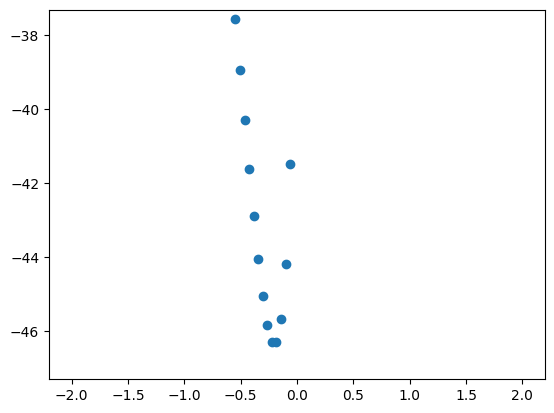

  0%|          | 1/15001 [00:00<44:44,  5.59it/s, alpha_star=2.0163e-01, min_epsilon=6.0463e-01, total_scale=7.824074e-04]

0.20163111729442423
Iteration 0, alpha_star=2.0163e-01, total_scale=7.824074e-04, min_epsilon=6.0463e-01


 20%|█▉        | 2999/15001 [04:21<12:59, 15.39it/s, alpha_star=2.0840e-02, min_epsilon=7.0355e-01, total_scale=1.905018e-04]

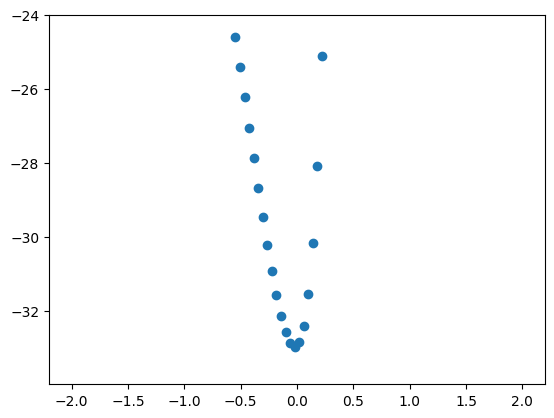

 20%|██        | 3003/15001 [04:21<16:19, 12.24it/s, alpha_star=6.4444e-03, min_epsilon=7.0363e-01, total_scale=7.311542e-05]

0.020839811875713432
Iteration 3000, alpha_star=2.0840e-02, total_scale=1.905018e-04, min_epsilon=7.0355e-01


 40%|███▉      | 5998/15001 [08:17<08:56, 16.77it/s, alpha_star=3.7882e-03, min_epsilon=8.5014e-01, total_scale=2.565998e-05]

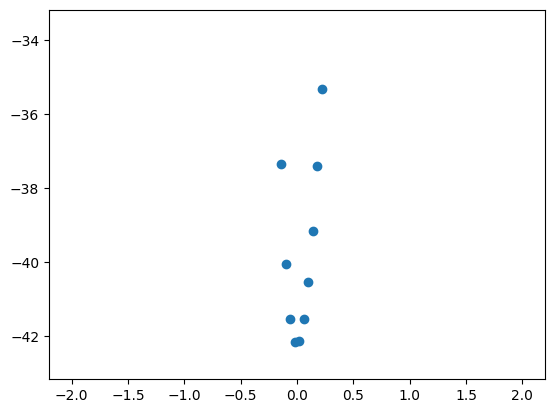

 40%|████      | 6003/15001 [08:17<08:54, 16.84it/s, alpha_star=1.0502e-02, min_epsilon=8.5032e-01, total_scale=4.711482e-05]

0.0037881964139805623
Iteration 6000, alpha_star=3.7882e-03, total_scale=2.565998e-05, min_epsilon=8.5014e-01


 60%|█████▉    | 8999/15001 [11:36<05:48, 17.22it/s, alpha_star=1.2007e-03, min_epsilon=8.9674e-01, total_scale=1.350561e-05]

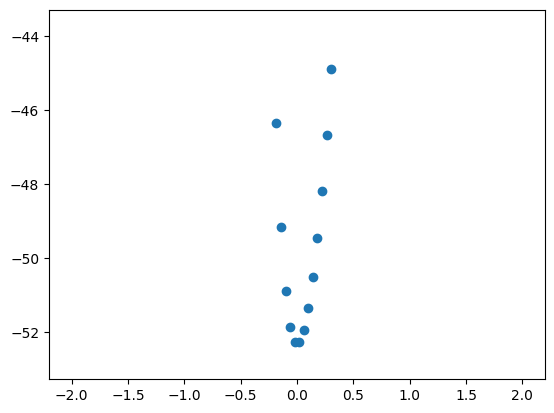

 60%|██████    | 9003/15001 [11:36<06:20, 15.75it/s, alpha_star=1.8169e-03, min_epsilon=8.9668e-01, total_scale=1.119083e-05]

0.0012007135291424067
Iteration 9000, alpha_star=1.2007e-03, total_scale=1.350561e-05, min_epsilon=8.9674e-01


 80%|███████▉  | 12000/15001 [13:57<01:55, 25.93it/s, alpha_star=2.4865e-04, min_epsilon=8.4735e-01, total_scale=4.076375e-06]

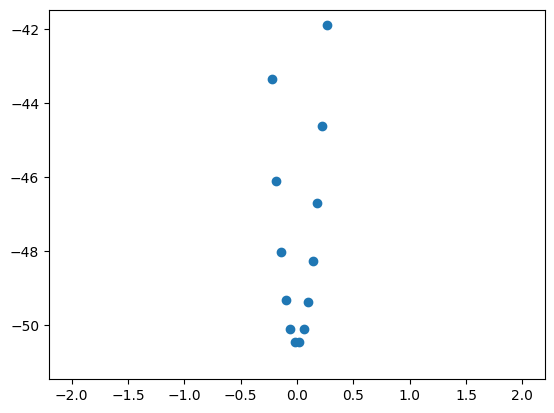

 80%|████████  | 12006/15001 [13:57<02:01, 24.60it/s, alpha_star=2.1690e-04, min_epsilon=8.4730e-01, total_scale=1.344744e-06]

0.00024865448290228723
Iteration 12000, alpha_star=2.4865e-04, total_scale=4.076375e-06, min_epsilon=8.4735e-01


100%|█████████▉| 14997/15001 [15:46<00:00, 28.91it/s, alpha_star=4.5560e-06, min_epsilon=8.3931e-01, total_scale=2.314820e-08]

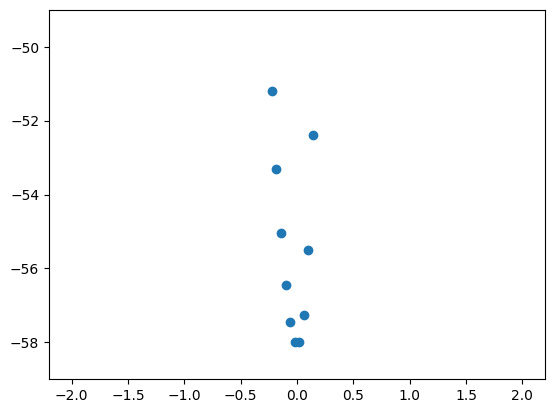

100%|██████████| 15001/15001 [15:46<00:00, 15.85it/s, alpha_star=4.5560e-06, min_epsilon=8.3931e-01, total_scale=2.314820e-08]

4.556012002742086e-06
Iteration 15000, alpha_star=4.5560e-06, total_scale=2.314820e-08, min_epsilon=8.3931e-01
optimization complete


In [11]:
new_params = optimizer.optimize(params_0, lr=1e-4, epoch=15001, print_period=3000, e_size=0.2, eN=9, sg=2)
print('optimization complete')


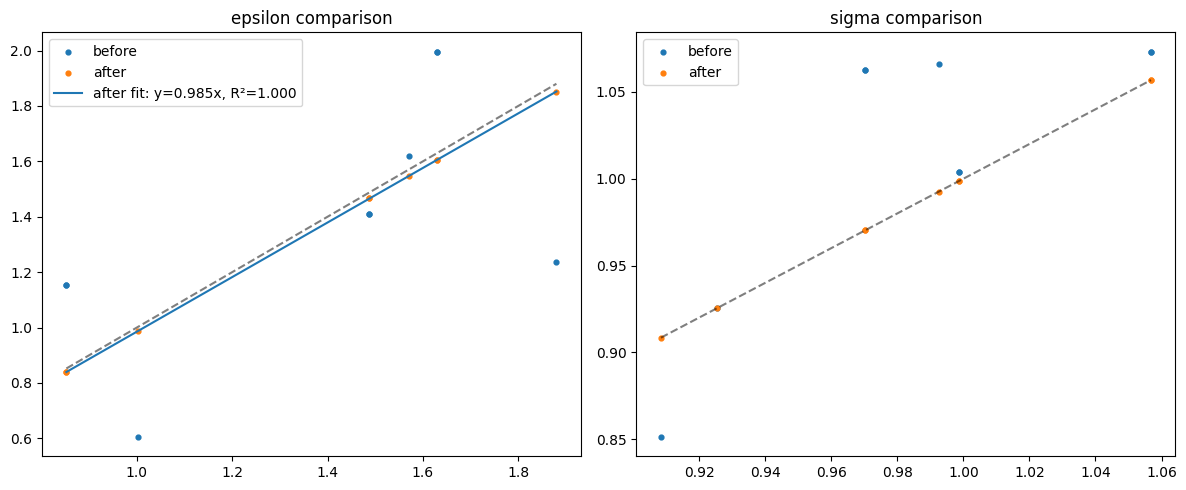

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_eps = params_star['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_eps = params_0['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_eps = new_params['epsilon'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_eps, before_eps, label='before', s=12)
plt.scatter(target_eps, after_eps, label='after', s=12)
plt.plot([target_eps.min(), target_eps.max()], [target_eps.min(), target_eps.max()], 'k--', alpha=0.5)
plt.title('epsilon comparison')

# Linear fits: y = a*x + b
def add_linear_fit(x, y, label, linestyle='-'):
    mask = np.isfinite(x) & np.isfinite(y)
    x_fit_data = x[mask]
    y_fit_data = y[mask]

    a = np.sum(x_fit_data * y_fit_data) / np.sum(x_fit_data**2)
    y_pred = a * x_fit_data

    r2 = 1 - np.sum((y_fit_data - y_pred)**2) / np.sum((y_fit_data - y_fit_data.mean())**2)

    x_line = np.linspace(x_fit_data.min(), x_fit_data.max(), 200)
    y_line = a * x_line

    plt.plot(
        x_line, y_line, linestyle,
        label=f'{label} fit: y={a:.3f}x, R²={r2:.3f}'
    )

add_linear_fit(target_eps, after_eps, 'after')

plt.legend()

plt.subplot(1, 2, 2)
target_sigma = params_star['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_sigma = params_0['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_sigma = new_params['sigma'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_sigma, before_sigma, label='before', s=12)
plt.scatter(target_sigma, after_sigma, label='after', s=12)
plt.plot([target_sigma.min(), target_sigma.max()], [target_sigma.min(), target_sigma.max()], 'k--', alpha=0.5)
plt.title('sigma comparison')
plt.legend()


plt.tight_layout()
